# 04 — Stacked Attention Network (SAN) | PathVQA

**Capstone:** Question-Type-Aware Multimodal Fusion for Pathology Visual Question Answering (QTAF-Net)

## Research goal
Train a **two-hop Stacked Attention Network (SAN) from scratch** to combine spatial CNN image features with BiLSTM question features. Each attention hop learns to weight image locations using the question-conditioned representation.

**Controlled setup:** PathVQA; same cleaned train/validation splits, 224×224 RGB image preprocessing, question vocabulary and top-1,000 answer mapping as the original CNN + BiLSTM baseline. Adam `lr=0.001`, batch 32, maximum 30 epochs, patience 5; fine-tuning from the best original checkpoint at `lr=0.0001` for up to 10 epochs, patience 3.

**No pretrained weights, embeddings, backbones, or attention.** The original late-fusion checkpoint is loaded only to restore token and answer dictionaries.

**Evaluation caveat:** Like the earlier baselines, metrics use **ground-truth answer-type (oracle) routing** to choose yes/no versus open-ended heads. OOV open answers count as wrong. Do not use test data for tuning.

**Run top to bottom**. When restoring trained SAN weights, skip the original and fine-tuning training loops.


## Submission guide: execution, dependencies and reproducibility

**Purpose.** This notebook trains a two-hop Stacked Attention Network (SAN) for PathVQA from scratch, then fine-tunes its best original checkpoint. It is a multimodal baseline for the QTAF-Net capstone.

**Environment.** Open in Kaggle with GPU enabled and Internet access for the Hugging Face dataset download. The notebook installs `datasets` and imports PyTorch, torchvision, NumPy, pandas, Pillow, matplotlib and other standard dependencies. Kaggle versions can change; record package versions when rerunning.

**Required input.** Attach a Kaggle dataset containing `late_fusion_latest.pth` from Notebook 01. This file supplies the *training-derived* `word2idx` and `open_answer2idx` mappings only; SAN weights are initialized independently. The notebook searches for this file recursively under `/kaggle/input`. The Hugging Face `flaviagiammarino/path-vqa` dataset must also be accessible.

**Run order.** (1) Run Notebook 01 first to create the vocabulary checkpoint. (2) Attach that checkpoint dataset. (3) Run this notebook's cells from top to bottom to clean the training split, encode data, build SAN, train the original model, evaluate the best original checkpoint, fine-tune, evaluate the best fine-tuned checkpoint, visualize attention, and export outputs. Fine-tuning depends on the original best checkpoint; skip no preceding training cells unless restoring the required files deliberately.

**Data protocol.** The test split is not used for model selection in this notebook. Validation results use *oracle answer-type routing*: the reference yes/no versus open type selects the relevant output head. This is not equivalent to predicted type routing at deployment. Final test metrics are computed in the separate shared evaluation notebook.

**Expected outputs.** The notebook writes original/fine-tuned SAN checkpoints, history files, plots and a backup ZIP under `/kaggle/working` (where supported by the code). Save these before the session expires. The displayed validation curves and attention maps are not substitutes for held-out test evaluation.

**Reproducibility note.** The notebook contains saved outputs from the author's run. The code has not been changed in this documented copy and has not been re-executed here. GPU determinism, package versions, network access and availability of input files can affect a fresh rerun.


## 1. Kaggle setup and imports

Create `04_Stacked_Attention_Network.ipynb`, enable a GPU (T4 recommended), and attach the original **1,000-answer** `late_fusion_latest.pth` as Kaggle Input. Allow Internet access if PathVQA must be downloaded.

In [8]:
# Install the dataset library and import dependencies; fix random seeds for repeatability.
!pip -q install datasets

import os, re, glob, hashlib, random, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 2. Load PathVQA and remove train/validation image overlap

Expected sizes: train 19,654, validation 6,259, test 6,719. The same overlap-cleaning procedure should leave **19,648 training examples**.

In [ ]:
# Load PathVQA and remove training examples whose image pixels duplicate validation images.
dataset = load_dataset("flaviagiammarino/path-vqa")
for split in ("train", "validation", "test"):
    print(split, len(dataset[split]))

def image_hash(image):
    image = image.convert("RGB")
    h = hashlib.sha256()
    h.update(str(image.size).encode())
    h.update(image.tobytes())
    return h.hexdigest()

val_hashes = {image_hash(s["image"]) for s in tqdm(dataset["validation"], desc="Hash validation")}
keep_indices = [
    i for i, s in enumerate(tqdm(dataset["train"], desc="Check training overlap"))
    if image_hash(s["image"]) not in val_hashes
]
clean_train = dataset["train"].select(keep_indices)
clean_val = dataset["validation"]
clean_test = dataset["test"]  # held out
print("Clean train:", len(clean_train), "Validation:", len(clean_val))
assert len(clean_train) == 19648, "Unexpected cleaning count; inspect dataset version."

README.md:   0%|          | 0.00/4.29k [00:00<?, ?B/s]

data/train-00000-of-00007-f2d0e9ef9f022d(…): reconstructing file:   0%|          |  0.00B / 42.8MB            

data/train-00000-of-00007-f2d0e9ef9f022d(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-47d8e0220bf6c9(…): reconstructing file:   0%|          |  0.00B / 81.0MB            

data/train-00001-of-00007-47d8e0220bf6c9(…): downloading bytes:           |  0.00B            

data/train-00002-of-00007-7fb5037c4c5da7(…): reconstructing file:   0%|          |  0.00B /  104MB            

... (24 outputs left out)

train 19654
validation 6259
test 6719


Hash validation:   0%|          | 0/6259 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Check training overlap:   0%|          | 0/19654 [00:00<?, ?it/s]

## 3. Restore the exact question and answer vocabularies

We restore **only mappings** from your original 1,000-class late-fusion checkpoint. SAN weights are initialized randomly. If multiple checkpoint paths appear, select the intended original checkpoint explicitly.

In [9]:
# Read the shared training-derived vocabularies from a previous checkpoint; do not reuse its model weights.
candidates = sorted(
    glob.glob("/kaggle/input/**/late_fusion_latest.pth", recursive=True)
    + glob.glob("/kaggle/working/late_fusion_latest.pth")
)
for i, path in enumerate(candidates):
    print(i, path)
if len(candidates) != 1:
    raise RuntimeError("Attach exactly one original late_fusion_latest.pth checkpoint.")
# Load only checkpoints you created and trust.
saved = torch.load(candidates[0], map_location="cpu", weights_only=False)
word2idx = saved["word2idx"]
open_answer2idx = saved["open_answer2idx"]
del saved
assert len(open_answer2idx) == 1000
assert word2idx["<PAD>"] == 0 and word2idx["<UNK>"] == 1
print("Question vocabulary:", len(word2idx))
print("Open answer vocabulary:", len(open_answer2idx))

0 /kaggle/input/datasets/dollarpaisa/cnn-bilstam/late_fusion_latest.pth
Question vocabulary: 3972
Open answer vocabulary: 1000


## 4. Encode questions and answers

Use the same lowercase regex tokenization, maximum question length 32, and yes/no mapping as your original baseline. Open-ended answers outside the top 1,000 are assigned `-1`.

In [10]:
# Convert each question into fixed-length token IDs and map answers to the fixed answer classes.
MAX_QUESTION_LENGTH = 32

def encode_question(text):
    tokens = re.findall(r"\w+|[^\w\s]", str(text).lower().strip())
    ids = [word2idx.get(token, word2idx["<UNK>"]) for token in tokens[:MAX_QUESTION_LENGTH]]
    return ids + [word2idx["<PAD>"]] * (MAX_QUESTION_LENGTH - len(ids))

def encode_answer(answer):
    answer = str(answer).lower().strip()
    if answer == "no": return 0, 0
    if answer == "yes": return 0, 1
    return 1, open_answer2idx.get(answer, -1)

open_total = open_covered = 0
for answer in clean_val["answer"]:
    kind, label = encode_answer(answer)
    if kind == 1:
        open_total += 1
        open_covered += int(label >= 0)
print(f"Open-answer coverage: {open_covered}/{open_total} = {open_covered/open_total:.2%}")

Open-answer coverage: 2086/3134 = 66.56%


## 5. Image preprocessing

Resize preserving aspect ratio, white-pad to **224×224**, convert to RGB float32 `[0,1]`. This matches the earlier CNN baseline; no pretrained normalization.

In [11]:
# Resize pathology images with preserved aspect ratio and white padding to 224 × 224.
IMAGE_SIZE = 224

def preprocess_image(image):
    image = image.convert("RGB")
    image = ImageOps.contain(image, (IMAGE_SIZE, IMAGE_SIZE), method=Image.Resampling.BILINEAR)
    background = Image.new("RGB", (IMAGE_SIZE, IMAGE_SIZE), (255, 255, 255))
    background.paste(image, ((IMAGE_SIZE - image.width)//2, (IMAGE_SIZE - image.height)//2))
    array = np.asarray(background, dtype=np.float32) / 255.0
    return torch.from_numpy(array).permute(2, 0, 1)

print("Image tensor:", preprocess_image(clean_train[0]["image"]).shape)

Image tensor: torch.Size([3, 224, 224])


## 6. Dataset and DataLoaders

Each example contains the image, question, true answer type and encoded answer label. Batch size 32, `num_workers=2`.

In [12]:
# Prepare image tensors, token IDs, answer types and labels for minibatch training.
class PathVQASANDataset(Dataset):
    def __init__(self, hf_split):
        self.data = hf_split
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        example = self.data[idx]
        answer_type, answer_label = encode_answer(example["answer"])
        return {
            "image": preprocess_image(example["image"]),
            "question": torch.tensor(encode_question(example["question"]), dtype=torch.long),
            "answer_type": torch.tensor(answer_type, dtype=torch.long),
            "answer_label": torch.tensor(answer_label, dtype=torch.long),
        }

train_dataset = PathVQASANDataset(clean_train)
val_dataset = PathVQASANDataset(clean_val)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2,
                          pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2,
                        pin_memory=torch.cuda.is_available())
batch = next(iter(train_loader))
for k, v in batch.items(): print(k, tuple(v.shape))
print("Train batches:", len(train_loader), "Validation batches:", len(val_loader))

image (32, 3, 224, 224)
question (32, 32)
answer_type (32,)
answer_label (32,)
Train batches: 614 Validation batches: 196


**Architecture note.** The spatial CNN retains a grid of image features rather than collapsing the image immediately to one vector. Each attention hop uses the encoded question to weight grid locations; the second hop refines the attended representation. This is the key difference from global late fusion.


## 7. SAN architecture — two spatial attention hops

The **CNN** matches the earlier four-convolution architecture, but retains its **28×28 spatial feature grid** instead of immediately applying global pooling. A trainable 1×1 projection maps 256 CNN channels to a 256-dimensional visual feature per location.

The **question encoder** uses trainable 128-dimensional embeddings and a bidirectional LSTM with hidden size 128 per direction (256-dimensional question representation).

At each of **two attention hops**, the current question-conditioned query and 784 visual locations produce attention scores. Softmax weights produce an attended visual vector, which is added to the query for the next hop. The final representation feeds the two answer heads.

**Everything is randomly initialized; no pretrained model is loaded.**

In [13]:
# Define the spatial CNN, bidirectional question encoder and two successive question-guided attention hops.
class SpatialImageEncoder(nn.Module):
    def __init__(self, feature_dim=256):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
        )
        self.project = nn.Conv2d(256, feature_dim, kernel_size=1)

    def forward(self, images):
        features = self.project(self.cnn(images))   # [B, 256, 28, 28]
        return features.flatten(2).transpose(1, 2) # [B, 784, 256]

class QuestionEncoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
    def forward(self, questions):
        embeddings = self.embedding(questions)
        lengths = (questions != 0).sum(dim=1).clamp(min=1)
        packed = nn.utils.rnn.pack_padded_sequence(
            embeddings, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)
        return torch.cat([hidden[-2], hidden[-1]], dim=1)

class AttentionHop(nn.Module):
    def __init__(self, feature_dim=256, attention_dim=256):
        super().__init__()
        self.visual = nn.Linear(feature_dim, attention_dim)
        self.query = nn.Linear(feature_dim, attention_dim)
        self.score = nn.Linear(attention_dim, 1)
    def forward(self, spatial_features, query):
        hidden = torch.tanh(self.visual(spatial_features) + self.query(query).unsqueeze(1))
        weights = torch.softmax(self.score(hidden).squeeze(-1), dim=1)
        attended = torch.sum(spatial_features * weights.unsqueeze(-1), dim=1)
        return query + attended, weights

class StackedAttentionNetwork(nn.Module):
    def __init__(self, vocab_size, num_open_answers=1000, num_hops=2):
        super().__init__()
        self.image_encoder = SpatialImageEncoder()
        self.question_encoder = QuestionEncoder(vocab_size)
        self.hops = nn.ModuleList([AttentionHop() for _ in range(num_hops)])
        self.classifier = nn.Sequential(nn.Linear(256, 256), nn.ReLU(), nn.Dropout(0.3))
        self.yes_no_head = nn.Linear(256, 2)
        self.open_head = nn.Linear(256, num_open_answers)

    def forward(self, images, questions, return_attention=False):
        visual = self.image_encoder(images)
        query = self.question_encoder(questions)
        maps = []
        for hop in self.hops:
            query, weights = hop(visual, query)
            if return_attention: maps.append(weights)
        features = self.classifier(query)
        outputs = (self.yes_no_head(features), self.open_head(features))
        return (*outputs, maps) if return_attention else outputs

model = StackedAttentionNetwork(
    vocab_size=len(word2idx), num_open_answers=len(open_answer2idx), num_hops=2
).to(device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable parameters: 1814764


## 8. Sanity-check tensor shapes

Before expensive training, verify output dimensions and attention normalization. **This is only a forward pass**, not training.

In [14]:
# Check the model output and attention tensor shapes before beginning training.
model.eval()
with torch.no_grad():
    small_images = batch["image"][:2].to(device)
    small_questions = batch["question"][:2].to(device)
    yes_no_logits, open_logits, attention_maps = model(
        small_images, small_questions, return_attention=True
    )
print("Yes/no:", tuple(yes_no_logits.shape))
print("Open:", tuple(open_logits.shape))
for i, weights in enumerate(attention_maps, start=1):
    print(f"Hop {i} attention:", tuple(weights.shape),
          "weight sums:", weights.sum(dim=1).cpu().tolist())
assert tuple(yes_no_logits.shape) == (2, 2)
assert tuple(open_logits.shape) == (2, 1000)
assert len(attention_maps) == 2

Yes/no: (2, 2)
Open: (2, 1000)
Hop 1 attention: (2, 784) weight sums: [1.0, 1.0]
Hop 2 attention: (2, 784) weight sums: [1.0, 1.0000001192092896]


**Metric note.** Yes/no and open-ended examples contribute to separate classification heads. Open answers outside the top-1,000 training answer vocabulary cannot be exactly predicted by that head. The validation function uses the ground-truth question type to select a head.


## 9. Two-head loss and validation

As in earlier baselines, average yes/no and covered-open cross-entropy when both types appear in a batch. Out-of-vocabulary open answers are excluded from training loss but **count as incorrect** in validation. Validation uses oracle answer-type routing.

In [15]:
# Compute the appropriate head loss and validation accuracy using ground-truth answer-type routing.
def compute_loss(yes_no_logits, open_logits, types, labels):
    closed = types == 0
    open_valid = (types == 1) & (labels >= 0)
    losses = []
    if closed.any():
        losses.append(F.cross_entropy(yes_no_logits[closed], labels[closed]))
    if open_valid.any():
        losses.append(F.cross_entropy(open_logits[open_valid], labels[open_valid]))
    if not losses:
        return (yes_no_logits.sum() + open_logits.sum()) * 0
    return sum(losses) / len(losses)

def train_one_epoch(model, loader, optimizer, device):
    model.train()
    loss_sum = count = 0
    for batch in tqdm(loader, desc="Training"):
        images = batch["image"].to(device, non_blocking=True)
        questions = batch["question"].to(device, non_blocking=True)
        types = batch["answer_type"].to(device)
        labels = batch["answer_label"].to(device)
        optimizer.zero_grad()
        yn, op = model(images, questions)
        loss = compute_loss(yn, op, types, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        size = images.shape[0]
        loss_sum += loss.item() * size
        count += size
    return loss_sum / count

@torch.no_grad()
def validate(model, loader, device):
    model.eval()
    closed_correct = closed_total = open_correct = open_total = 0
    for batch in tqdm(loader, desc="Validation"):
        images = batch["image"].to(device, non_blocking=True)
        questions = batch["question"].to(device, non_blocking=True)
        types = batch["answer_type"].to(device)
        labels = batch["answer_label"].to(device)
        yn, op = model(images, questions)
        closed = types == 0
        opened = types == 1
        closed_correct += ((yn.argmax(1) == labels) & closed).sum().item()
        open_correct += ((op.argmax(1) == labels) & opened).sum().item()
        closed_total += closed.sum().item()
        open_total += opened.sum().item()
    return {
        "overall_accuracy": (closed_correct + open_correct) / max(closed_total + open_total, 1),
        "closed_accuracy": closed_correct / max(closed_total, 1),
        "open_accuracy": open_correct / max(open_total, 1),
    }
print("Loss, training, validation functions ready.")

Loss, training, validation functions ready.


## 10. Original SAN training — up to 30 epochs

Adam `lr=0.001`, weight decay `1e-5`, early stopping patience **5**. Best weights are selected by **overall validation accuracy** and saved independently of the latest resumable checkpoint.

**Skip this cell when restoring a trained original SAN.** A two-hop SAN over 784 spatial positions may be slower and use more GPU memory than late fusion; if out of memory, reduce batch size and document the change.

In [16]:
# Train SAN from scratch, tracking validation performance and saving the best original checkpoint.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
MAX_EPOCHS = 30
PATIENCE = 5
best_accuracy, best_epoch, no_improvement = -1.0, 0, 0
history = []

best_path = "/kaggle/working/best_san.pth"
latest_path = "/kaggle/working/san_latest.pth"
history_path = "/kaggle/working/san_history.csv"

for epoch in range(1, MAX_EPOCHS + 1):
    loss = train_one_epoch(model, train_loader, optimizer, device)
    metrics = validate(model, val_loader, device)
    overall = metrics["overall_accuracy"]
    history.append({
        "epoch": epoch, "train_loss": loss, "overall_accuracy": overall,
        "yes_no_accuracy": metrics["closed_accuracy"], "open_accuracy": metrics["open_accuracy"]
    })
    print(f"Epoch {epoch:02d} | Loss: {loss:.4f} | Overall: {overall:.2%} | "
          f"Yes/No: {metrics['closed_accuracy']:.2%} | Open: {metrics['open_accuracy']:.2%}")
    if overall > best_accuracy:
        best_accuracy, best_epoch, no_improvement = overall, epoch, 0
        torch.save(model.state_dict(), best_path)
        print("New best SAN saved!")
    else:
        no_improvement += 1
    torch.save({
        "epoch": epoch, "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(), "history": history,
        "best_accuracy": best_accuracy, "best_epoch": best_epoch,
        "word2idx": word2idx, "open_answer2idx": open_answer2idx,
        "model_name": "SAN_2hop"
    }, latest_path)
    pd.DataFrame(history).to_csv(history_path, index=False)
    if no_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print("Best original SAN epoch:", best_epoch)
print(f"Best original SAN accuracy: {best_accuracy:.2%}")

Training:   0%|          | 0/614 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Epoch 01 | Loss: 2.6030 | Overall: 46.38% | Yes/No: 82.43% | Open: 10.43%
New best SAN saved!


Training:   0%|          | 0/614 [00:00<?, ?it/s]

... (140 outputs left out)

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7913711f67a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7913711f67a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/p

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Epoch 30 | Loss: 0.8855 | Overall: 53.49% | Yes/No: 85.82% | Open: 21.25%
Best original SAN epoch: 28
Best original SAN accuracy: 53.84%


## 11. Evaluate the best original SAN

Restore the **best saved weights**, not the last epoch. This also works if you upload `best_san.pth` as Kaggle Input in a later session.

In [17]:
# Reload the best original weights and report validation results rather than using the last epoch.
original_candidates = (
    glob.glob("/kaggle/working/best_san.pth")
    + glob.glob("/kaggle/input/**/best_san.pth", recursive=True)
)
if not original_candidates:
    raise FileNotFoundError("Train SAN or attach best_san.pth.")
original_best_checkpoint = original_candidates[0]
model.load_state_dict(torch.load(original_best_checkpoint, map_location=device, weights_only=True))
original_metrics = validate(model, val_loader, device)
print("BEST ORIGINAL SAN")
print(f"Overall: {original_metrics['overall_accuracy']:.2%}")
print(f"Yes/No: {original_metrics['closed_accuracy']:.2%}")
print(f"Open: {original_metrics['open_accuracy']:.2%}")
print("Checkpoint:", original_best_checkpoint)

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


BEST ORIGINAL SAN
Overall: 53.84%
Yes/No: 86.08%
Open: 21.70%
Checkpoint: /kaggle/working/best_san.pth


**Fine-tuning note.** This is continued optimization of the SAN weights saved during original training, not a pretrained external model. Compare the best validation checkpoints, not merely the final epochs.


## 12. Fine-tune SAN from its own best checkpoint

Continue training **your own** best SAN weights using a **new Adam optimizer**, learning rate `0.0001`, weight decay `1e-5`, up to **10 additional epochs**, patience **3**. Save fine-tuned files separately so the original remains intact.

**Skip this cell if fine-tuning has already been completed.**

In [18]:
# Continue from the best original checkpoint with a smaller learning rate and save the best fine-tuned weights.
model.load_state_dict(torch.load(original_best_checkpoint, map_location=device, weights_only=True))
optimizer_ft = torch.optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-5)
FT_EPOCHS, FT_PATIENCE = 10, 3
best_ft_accuracy, best_ft_epoch, ft_no_improvement = -1.0, 0, 0
ft_history = []

ft_best_path = "/kaggle/working/best_san_finetuned.pth"
ft_latest_path = "/kaggle/working/san_finetune_latest.pth"
ft_history_path = "/kaggle/working/san_finetune_history.csv"

for epoch in range(1, FT_EPOCHS + 1):
    loss = train_one_epoch(model, train_loader, optimizer_ft, device)
    metrics = validate(model, val_loader, device)
    overall = metrics["overall_accuracy"]
    ft_history.append({
        "finetune_epoch": epoch, "train_loss": loss,
        "overall_accuracy": overall, "yes_no_accuracy": metrics["closed_accuracy"],
        "open_accuracy": metrics["open_accuracy"]
    })
    print(f"Fine-tune epoch {epoch:02d} | Loss: {loss:.4f} | Overall: {overall:.2%} | "
          f"Yes/No: {metrics['closed_accuracy']:.2%} | Open: {metrics['open_accuracy']:.2%}")
    if overall > best_ft_accuracy:
        best_ft_accuracy, best_ft_epoch, ft_no_improvement = overall, epoch, 0
        torch.save(model.state_dict(), ft_best_path)
        print("New best fine-tuned SAN saved!")
    else:
        ft_no_improvement += 1
    torch.save({
        "finetune_epoch": epoch, "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer_ft.state_dict(), "history": ft_history,
        "best_accuracy": best_ft_accuracy, "best_epoch": best_ft_epoch,
        "word2idx": word2idx, "open_answer2idx": open_answer2idx,
        "model_name": "SAN_2hop_finetuned", "initial_checkpoint": original_best_checkpoint
    }, ft_latest_path)
    pd.DataFrame(ft_history).to_csv(ft_history_path, index=False)
    if ft_no_improvement >= FT_PATIENCE:
        print("Fine-tuning early stopping triggered.")
        break

print("Best additional fine-tuning epoch:", best_ft_epoch)
print(f"Best fine-tuned SAN accuracy: {best_ft_accuracy:.2%}")

Training:   0%|          | 0/614 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7913711f67a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7913711f67a0><function _MultiProcessingDataLoaderIter.__del__ at 0x7913711f67a0>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/u

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Fine-tune epoch 01 | Loss: 0.7944 | Overall: 54.39% | Yes/No: 86.02% | Open: 22.85%
New best fine-tuned SAN saved!


Training:   0%|          | 0/614 [00:00<?, ?it/s]

... (10 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7913711f67a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7913711f67a0>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7913711f67a0>    
Traceback (most recent call last):
self._shutdown_workers()  File "/usr/local/lib/pyth

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Fine-tune epoch 04 | Loss: 0.7080 | Overall: 54.37% | Yes/No: 86.14% | Open: 22.69%
Fine-tuning early stopping triggered.
Best additional fine-tuning epoch: 1
Best fine-tuned SAN accuracy: 54.39%


## 13. Evaluate the best fine-tuned SAN

Always evaluate the **best fine-tuned checkpoint** rather than the final fine-tuning epoch.

In [19]:
# Evaluate the best fine-tuned checkpoint using the same validation protocol.
ft_candidates = (
    glob.glob("/kaggle/working/best_san_finetuned.pth")
    + glob.glob("/kaggle/input/**/best_san_finetuned.pth", recursive=True)
)
if not ft_candidates:
    raise FileNotFoundError("Fine-tune SAN or attach best_san_finetuned.pth.")
model.load_state_dict(torch.load(ft_candidates[0], map_location=device, weights_only=True))
finetuned_metrics = validate(model, val_loader, device)
print("BEST FINE-TUNED SAN")
print(f"Overall accuracy: {finetuned_metrics['overall_accuracy']:.2%}")
print(f"Yes/No accuracy: {finetuned_metrics['closed_accuracy']:.2%}")
print(f"Open-ended accuracy: {finetuned_metrics['open_accuracy']:.2%}")
print("Checkpoint:", ft_candidates[0])

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


BEST FINE-TUNED SAN
Overall accuracy: 54.39%
Yes/No accuracy: 86.02%
Open-ended accuracy: 22.85%
Checkpoint: /kaggle/working/best_san_finetuned.pth


**Interpretation note.** An attention heatmap indicates where the model places learned spatial weight for the illustrated example; it does not establish that the highlighted region caused a correct answer or constitutes a clinical explanation.


## 14. Plot attention maps from both hops

Visualize learned spatial attention over a validation image. These **28×28** attention maps are interpolated to **224×224** for display. Attention maps are useful diagnostics but are **not guaranteed explanations** of model decisions.

This cell uses the **currently loaded model** (after Section 13, the fine-tuned SAN).

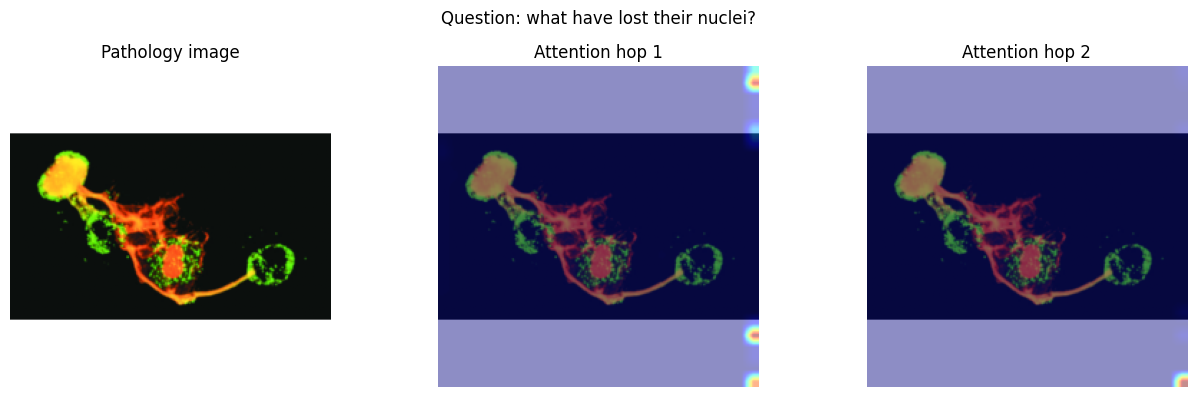

In [20]:
# Display spatial attention from both hops for a selected validation question; these maps are illustrative.
model.eval()
example = clean_val[0]
image = preprocess_image(example["image"])
question = torch.tensor(encode_question(example["question"]), dtype=torch.long)
with torch.no_grad():
    _, _, maps = model(
        image.unsqueeze(0).to(device),
        question.unsqueeze(0).to(device),
        return_attention=True
    )
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(image.permute(1, 2, 0).numpy())
axes[0].set_title("Pathology image")
for hop_idx in range(2):
    att = maps[hop_idx][0].reshape(1, 1, 28, 28)
    att = F.interpolate(att, size=(224, 224), mode="bilinear", align_corners=False)
    axes[hop_idx + 1].imshow(image.permute(1, 2, 0).numpy())
    axes[hop_idx + 1].imshow(att[0, 0].cpu().numpy(), cmap="jet", alpha=0.45)
    axes[hop_idx + 1].set_title(f"Attention hop {hop_idx + 1}")
for ax in axes: ax.axis("off")
plt.suptitle("Question: " + str(example["question"])[:100])
plt.tight_layout()
plt.show()

## 15. Training curves and experiment comparison

Previous baseline values below are **reported results from your earlier Kaggle runs**, not re-evaluations in this notebook. The SAN rows are evaluated from saved checkpoints.

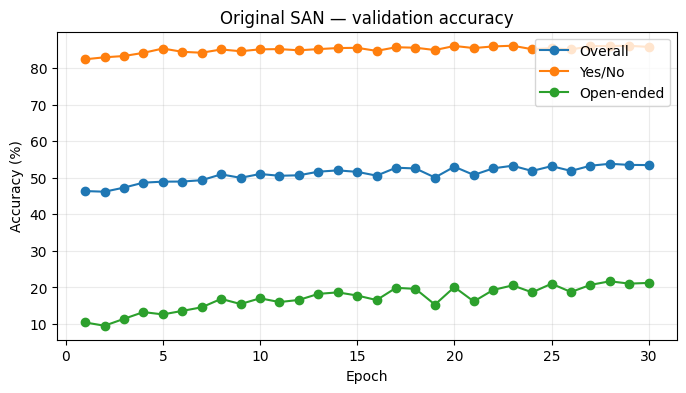

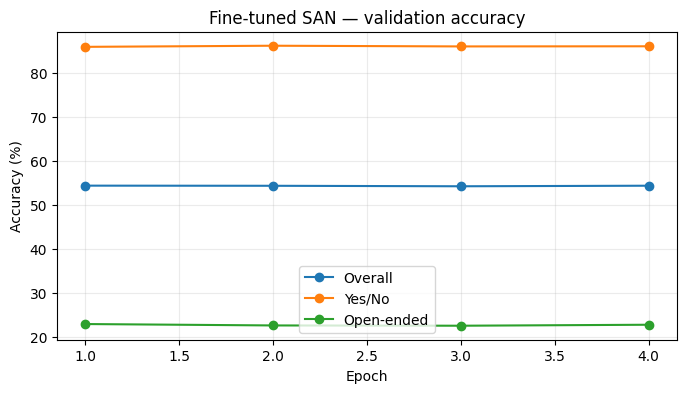

,Model,Overall (%),Yes/No (%),Open (%)
0,Image-Only CNN (fine-tuned),32.21,54.69,9.80
1,Question-Only BiLSTM (fine-tuned),48.20,85.25,11.26
2,CNN + BiLSTM (fine-tuned),54.42,86.43,22.50
3,SAN (original),53.84,86.08,21.70
4,SAN (fine-tuned),54.39,86.02,22.85


In [21]:
# Plot saved training histories and compare validation scores with the previously reported baselines.
def load_history(name):
    matches = (
        glob.glob("/kaggle/working/" + name)
        + glob.glob("/kaggle/input/**/" + name, recursive=True)
    )
    return pd.read_csv(matches[0]) if matches else None

for title, filename, xcol in [
    ("Original SAN", "san_history.csv", "epoch"),
    ("Fine-tuned SAN", "san_finetune_history.csv", "finetune_epoch")
]:
    df = load_history(filename)
    if df is None:
        print("History not found:", filename)
        continue
    plt.figure(figsize=(8, 4))
    for col, label in [
        ("overall_accuracy", "Overall"), ("yes_no_accuracy", "Yes/No"),
        ("open_accuracy", "Open-ended")
    ]:
        plt.plot(df[xcol], df[col] * 100, marker="o", label=label)
    plt.title(title + " — validation accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()

comparison = pd.DataFrame([
    {"Model": "Image-Only CNN (fine-tuned)", "Overall (%)": 32.21, "Yes/No (%)": 54.69, "Open (%)": 9.80},
    {"Model": "Question-Only BiLSTM (fine-tuned)", "Overall (%)": 48.20, "Yes/No (%)": 85.25, "Open (%)": 11.26},
    {"Model": "CNN + BiLSTM (fine-tuned)", "Overall (%)": 54.42, "Yes/No (%)": 86.43, "Open (%)": 22.50},
    {"Model": "SAN (original)", "Overall (%)": 100*original_metrics["overall_accuracy"],
     "Yes/No (%)": 100*original_metrics["closed_accuracy"],
     "Open (%)": 100*original_metrics["open_accuracy"]},
    {"Model": "SAN (fine-tuned)", "Overall (%)": 100*finetuned_metrics["overall_accuracy"],
     "Yes/No (%)": 100*finetuned_metrics["closed_accuracy"],
     "Open (%)": 100*finetuned_metrics["open_accuracy"]},
])
display(comparison.round(2))
comparison.to_csv("/kaggle/working/san_baseline_comparison.csv", index=False)

## 16. Backup all SAN results

Download `san_experiment_backup.zip` before the Kaggle session ends. This includes both best weights, resumable checkpoints, training histories and comparison CSV when available.

In [22]:
# Bundle available checkpoints, histories and figures for archiving outside the Kaggle session.
filenames = [
    "best_san.pth", "san_latest.pth", "san_history.csv",
    "best_san_finetuned.pth", "san_finetune_latest.pth",
    "san_finetune_history.csv", "san_baseline_comparison.csv"
]
zip_path = "/kaggle/working/san_experiment_backup.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for filename in filenames:
        path = "/kaggle/working/" + filename
        if os.path.isfile(path):
            zf.write(path, arcname=filename)
            print("Added:", filename)
        else:
            print("Not yet available:", filename)
print("Backup ready:", zip_path)

Added: best_san.pth
Added: san_latest.pth
Added: san_history.csv
Added: best_san_finetuned.pth
Added: san_finetune_latest.pth
Added: san_finetune_history.csv
Added: san_baseline_comparison.csv
Backup ready: /kaggle/working/san_experiment_backup.zip
